# MFQDMA: Quantile Detrending Moving Average for Multifractal Time Series and Surfaces

Reference: **S. Pratiher**, *Quantile Detrending Moving Average Algorithm for Multifractal Time Series and Surfaces*, submitted to a journal (2026).

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/<YOUR-GITHUB-USERNAME>/MFQDMA-PaperI/blob/main/MFQDMA_PaperI.ipynb)

This single notebook regenerates **all 17 figures and all 11 data tables** of the paper.

| Part | What it does | Run time (one core) |
|---|---|---|
| 0. Setup | clones the repository (Colab), installs the requirements | < 1 min |
| 1. Recompute (optional) | re-runs the numerical experiments and overwrites `results/` | off by default; 5 min – 1 h per group, see the flags |
| 2. Figures 1–17 | draws every figure from `results/` (Figs. 1–4, 7, 17 are computed directly) | about 10 min |
| 3. Tables II–XII | generates every data table from `results/` (LaTeX rows in `tables_out/`) | seconds |
| 4. Check | compares the regenerated figures with the manuscript figures in `figures/` | seconds |
| 5. Download | zips `figures_out/`, `tables_out/` and `results/` | seconds |

By default the notebook uses the stored results in `results/`, so **Runtime → Run all** reproduces the paper in about ten minutes. To regenerate the results themselves from scratch, switch on the flags in Part 1. All random seeds are fixed, so the recomputed results reproduce the stored ones.

**Data.** Synthetic data are generated in the code. Daily prices come from the CRAN package *qrmdata* (Hofert, Hornik & McNeil), which is cloned automatically from GitHub and read by a pure-Python parser (R is not needed). The terrain model ships with Matplotlib. The Bonn EEG database (Andrzejak *et al.*, Phys. Rev. E **64**, 061907, 2001) is needed only to *recompute* the EEG results (Part 1).

## 0. Setup

In [1]:
#@title Setup (run first): clone the repository in Colab and install requirements
import os, sys, subprocess
GITHUB_REPO = 'https://github.com/Sawon1234/MFQDMA.git'   # <- updated to valid GitHub repository URL
SUBDIR = ''          # path of this folder inside the repository, if it is not the repository root

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    root = '/content/' + GITHUB_REPO.rstrip('/').split('/')[-1].replace('.git', '')
    if not os.path.isdir(root):
        subprocess.run(['git', 'clone', '--depth', '1', GITHUB_REPO, root], check=True)
    os.chdir(os.path.join(root, SUBDIR))
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)
if not os.path.isdir('mfqdma'):
    raise RuntimeError('Run this notebook from the folder that contains MFQDMA_PaperI.ipynb and mfqdma/ '
                       '(in Colab: set GITHUB_REPO and SUBDIR above).')
sys.path.insert(0, os.getcwd())
try:
    from IPython.display import display, Markdown
except ImportError:                      # plain Python (no Jupyter): print instead
    display = print
    Markdown = str
import time, json, numpy as np, pandas as pd, matplotlib
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
print('working directory:', os.getcwd(), '| numpy', np.__version__, '| matplotlib', matplotlib.__version__)

working directory: /content/MFQDMA | numpy 2.4.6 | matplotlib 3.10.0


## 1. Recompute the stored results (optional)

Each flag re-runs one group of experiments and overwrites the corresponding file in `results/`. Leave everything `False` to reproduce the paper from the stored results. Run times are rough estimates for a free Colab runtime (measured on one CPU core and rounded up). With `RECOMPUTE_ALL = True` the whole study takes about 2 h.

In [2]:
RECOMPUTE_ALL = True
# RECOMPUTE_ALL = False

In [3]:
RECOMPUTE = dict(
    corpus_1d   = False,   # results/bench_1d.json       Tables II, III             ~10 min
    advantage   = False,   # results/advantage_all.json  Table IV, Figs. 5, 6       ~45 min
    analysis_2d = False,   # results/analysis_2d_all.json Table V, Figs. 8, 9       ~25 min
    mono_2d     = False,   # results/paper_2d_mono.json  Table VI, Fig. 9           ~5 min
    finance     = False,   # results/finance.json        Tables VII, VIII, Figs. 10-13 ~15 min
    dem         = False,   # results/dem.json            Table XII                  ~5 min
    eeg         = False,   # results/real_eeg.json, eeg_main.npz, eeg_auc.json, eeg_preproc.json
                           #                             Tables IX-XI, Figs. 14-16  ~10 min, needs the Bonn data
)
if RECOMPUTE_ALL:
    RECOMPUTE = {k: True for k in RECOMPUTE}
from mfqdma import experiments_paperI as E
print({k: v for k, v in RECOMPUTE.items() if v} or 'using the stored results in results/')

{'corpus_1d': True, 'advantage': True, 'analysis_2d': True, 'mono_2d': True, 'finance': True, 'dem': True, 'eeg': True}


### 1a. Synthetic benchmarks

In [4]:
if RECOMPUTE['corpus_1d']:
    E.run_corpus_1d()        # 8 binomial measures, 18 fGn series, 11 estimators
if RECOMPUTE['advantage']:
    E.run_advantage()        # contamination, alpha-stable noise, monotone maps, asymmetric cascades
if RECOMPUTE['analysis_2d']:
    E.run_analysis_2d()      # 2D cascades (theta x lambda), raw fBm surfaces, contaminated 2D cascades
if RECOMPUTE['mono_2d']:
    E.run_2d_mono()          # mixed increments of fractional Brownian surfaces

binomial p=0.25 done 20s
binomial p=0.3 done 37s
binomial p=0.35 done 54s
binomial p=0.4 done 69s
fGn H=0.2 done 167s
fGn H=0.3 done 256s
fGn H=0.5 done 330s
fGn H=0.7 done 398s
fGn H=0.8 done 466s
fGn H=0.9 done 536s
saved results/bench_1d.json
contamination done
levy done
monotonic done
asymmetry done
saved results/advantage_all.json
  A A k=8 done
  A A k=9 done
  A B k=8 done
  A B k=9 done
  A C k=8 done
  A C k=9 done
A done 469s
  B H=0.3 s=0 done
  B H=0.5 s=0 done
  B H=0.7 s=0 done
  B H=0.9 s=0 done
B done 516s
  C outlier f=0.0 done
  C outlier f=0.01 done
  C outlier f=0.02 done
  C outlier f=0.05 done
  C outlier f=0.1 done
  C student_t f=0.0 done
  C student_t f=0.01 done
  C student_t f=0.02 done
  C student_t f=0.05 done
  C student_t f=0.1 done
C done 735s
saved results/analysis_2d_all.json
H=0.2 done
H=0.2 done
H=0.2 done
H=0.3 done
H=0.3 done
H=0.3 done
H=0.5 done
H=0.5 done
H=0.5 done
H=0.7 done
H=0.7 done
H=0.7 done
H=0.9 done
H=0.9 done
H=0.9 done
saved results/

### 1b. Financial markets and terrain

In [5]:
if RECOMPUTE['finance']:
    E.run_finance()          # 18 assets + 29 DJIA stocks; clones github.com/cran/qrmdata on first use
if RECOMPUTE['dem']:
    E.run_dem()              # terrain elevation model and its surrogates

cloning https://github.com/cran/qrmdata ...
  A/B SP500 N=16606 done
  A/B DJ N=7796 done
  A/B NASDAQ N=7627 done
  A/B FTSE N=8332 done
  A/B DAX N=6354 done
  A/B CAC N=6548 done
  A/B SMI N=6349 done
  A/B EURSTOXX N=7444 done
  A/B NIKKEI N=7879 done
  A/B HSI N=7213 done
  A/B SSEC N=6391 done
  A/B CSI N=2662 done
  A/B EUR_USD N=4173 done
  A/B GBP_USD N=4173 done
  A/B JPY_USD N=4173 done
  A/B GOLD N=9690 done
  A/B OIL_Brent N=7257 done
  A/B BTC N=2873 done
AB saved 102s
  C SP500 done
  C DJ done
  C NASDAQ done
  C FTSE done
  C DAX done
  C CAC done
  C SMI done
  C EURSTOXX done
  C NIKKEI done
  C HSI done
  C SSEC done
  C CSI done
  C EUR_USD done
  C GBP_USD done
  C JPY_USD done
  C GOLD done
  C OIL_Brent done
  C BTC done
C saved 156s
  F done
F saved 192s
  D SP500 done
  D DJ done
  D NASDAQ done
  D FTSE done
  D DAX done
  D CAC done
  D SMI done
  D EURSTOXX done
  D NIKKEI done
  D HSI done
  D SSEC done
  D CSI done
  D EUR_USD done
  D GBP_USD done
  D JP

### 1c. Bonn EEG (only if `RECOMPUTE['eeg']`)

The Bonn EEG database is not redistributed here. Download the five sets Z, O, N, F, S (100 text files each) from the University of Bonn epileptology department (see Andrzejak *et al.* 2001), then point `BONN_SOURCE` at them. It may be a folder, a list of the five zip files, or one archive such as `Dataset.rar`. In Colab, upload the files with the folder icon on the left or mount Google Drive.

In [8]:
BONN_SOURCE = []   # e.g. ['/content/drive/MyDrive/Dataset.rar'] or ['z.zip', 'o.zip', 'n.zip', 'f.zip', 's.zip']
if RECOMPUTE['eeg']:
    from mfqdma import paths
    try:
        if not (paths.BONN / 'Z').is_dir():
            if IN_COLAB and any(str(s).lower().endswith('.rar') for s in BONN_SOURCE):
                subprocess.run('apt-get -qq install -y unrar > /dev/null', shell=True)
            paths.prepare_bonn(*BONN_SOURCE)
        E.run_eeg_preprocessing()    # Table IX
        E.run_eeg_surrogates()       # Table X, Fig. 14
        E.run_eeg_main()             # Figs. 15, 16
        E.run_eeg_classification()   # Table XI, Fig. 16(d)
    except FileNotFoundError as e:
        print(f'Warning: Skipping EEG recomputation because the Bonn dataset was not found: {e}')
        print('To fix this, upload the five ZIP files (z.zip, o.zip, etc.) or Dataset.rar, specify their paths in BONN_SOURCE above, or set RECOMPUTE["eeg"] = False to use the precomputed results.')

To fix this, upload the five ZIP files (z.zip, o.zip, etc.) or Dataset.rar, specify their paths in BONN_SOURCE above, or set RECOMPUTE["eeg"] = False to use the precomputed results.


## 2. Figures

Each cell draws one figure of the paper, shows it, and writes it to `figures_out/` as PDF and PNG. The plotting code is in `mfqdma/figures_paperI.py` (one function per figure). Figures 1–4, 7 and 17 are computed directly; their intermediate results are cached in `cache/`.

In [9]:
from mfqdma import figures_paperI as F
from mfqdma import paths
for p in paths.CACHE.glob('*.npy'):   # fresh start: recompute the direct computations
    p.unlink()

### Fig. 1. The 1D MFQDMA algorithm

The 1D MFQDMA algorithm on an fGn with $H=0.7$ ($N=2^{14}$, $\theta=0$, $n=128$). (a) Profile $y(i)$ with the moving mean of MFDMA and the moving quantiles $\tilde y_\lambda$ for $\lambda=0.1$, $0.5$, $0.9$. (b) Residuals $\epsilon(i)$ of MFDMA and $\epsilon_\lambda(i)$ for $\lambda=0.1$ and $0.9$. (c) $F_2(n,\lambda)$ for MFDMA and five quantile levels; the slopes $h(2,\lambda)$ are given in the legend.

*Source:* Computed directly (a few seconds).

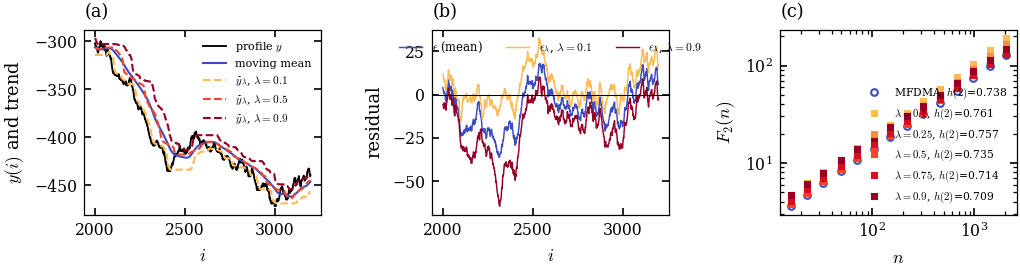

wrote /content/MFQDMA/figures_out/Fig01_schematic.pdf
Fig. 1 (Fig01_schematic) done in 6 s


'Fig01_schematic'

In [10]:
F.make_figure(1)

### Fig. 2. Binomial measure

Binomial measure, $p=0.3$, $N=2^{16}$. (a) $F_q(n)$ of backward MFQDMA ($\lambda=0.25$) for $q=-4,-2,0,2,4$, shifted vertically for clarity; lines are least-squares fits. (b) $\tau(q)$ from MFDFA, backward MFDMA, and backward MFQDMA versus theory. (c) $\Delta\tau(q)$ for all methods and five quantile levels. (d) Singularity spectra versus theory.

*Source:* Computed directly (a few seconds).

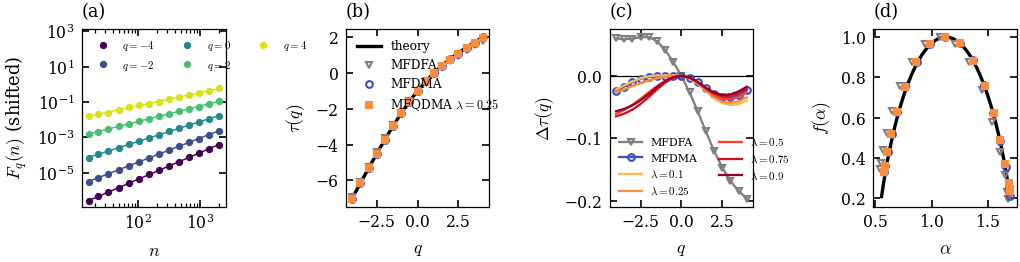

wrote /content/MFQDMA/figures_out/Fig02_binomial1d.pdf
Fig. 2 (Fig02_binomial1d) done in 8 s


'Fig02_binomial1d'

In [11]:
F.make_figure(2)

### Fig. 3. Gliding-box representation and degeneracy line

Proposition 1 and the degeneracy line. (a) A monotone profile of a binomial measure ($p=0.3$) with a backward window (shaded, $n=33$). The $\lambda=0.25$ quantile (dashed) equals $y(i-\ell)$, so $\epsilon_\lambda(i)$ is the box mass $\mu(i-\ell,i]$. (b) Standard deviation of the residual versus $\theta$ ($n=65$), normalized by that of backward MFDMA. Dotted lines mark $\theta=1-\lambda$. (c) $\mathrm{RMSE}_\tau$ versus $\theta$ for $N=2^{16}$.

*Source:* Computed directly (about 2 min; cached in `cache/`).

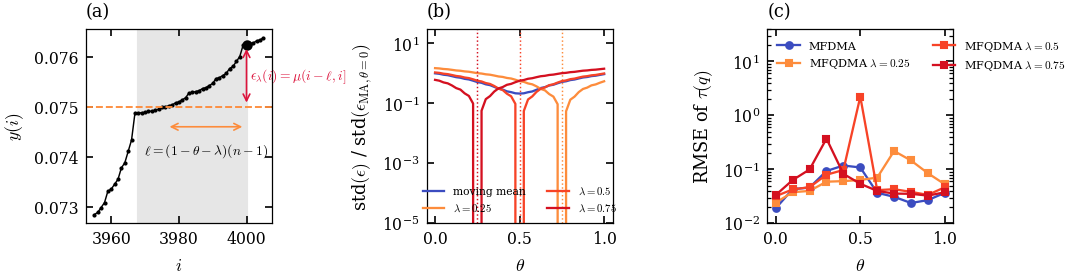

wrote /content/MFQDMA/figures_out/Fig03_boxsum_degeneracy.pdf
Fig. 3 (Fig03_boxsum_degeneracy) done in 118 s


'Fig03_boxsum_degeneracy'

In [12]:
F.make_figure(3)

### Fig. 4. λ independence for measures; monofractal fGn

(a) Corollary 2: $h(q,\lambda)$ of a binomial measure ($p=0.3$, $N=2^{16}$) for five quantile levels, compared with MFDMA and with theory. (b) $h(2)$ versus $H$ for fGn (mean $\pm$ s.d. of three realizations, $N=2^{16}$); the line is $h=H$. (c) Spurious width $\max_qh(q)-\min_qh(q)$ for fGn.

*Source:* Computed directly (18 fGn series of length $2^{16}$, about 3 min; cached in `cache/`).

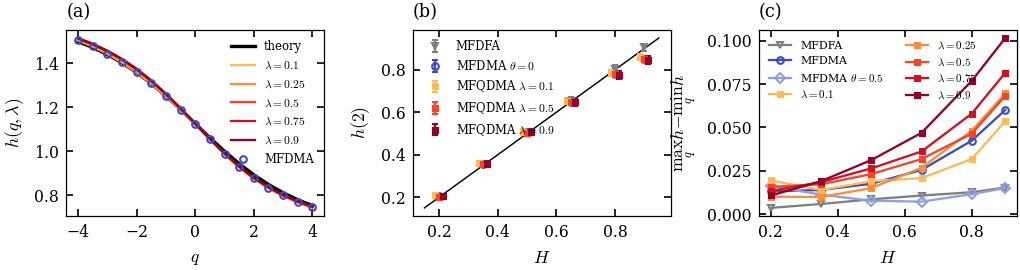

wrote /content/MFQDMA/figures_out/Fig04_lambda_invariance_monofractal.pdf
Fig. 4 (Fig04_lambda_invariance_monofractal) done in 237 s


'Fig04_lambda_invariance_monofractal'

In [13]:
F.make_figure(4)

### Fig. 5. Contaminated binomial measure

Robustness of $\tau(q)$ estimates of a contaminated binomial measure ($p=0.3$, $N=2^{16}$). (a)--(c) $\mathrm{RMSE}_\tau$ versus the contaminated fraction $\varepsilon$ for three contamination types (mean of five replicates). (d) Ratio $\mathrm{RMSE}_\tau(\mathrm{MFQDMA})/\mathrm{RMSE}_\tau(\mathrm{MFDMA})$ for $\lambda=0.1$, $0.25$, $0.9$, paired by replicate; values below the horizontal line favor MFQDMA.

*Source:* Reads `advantage_all.json` in `results/`.

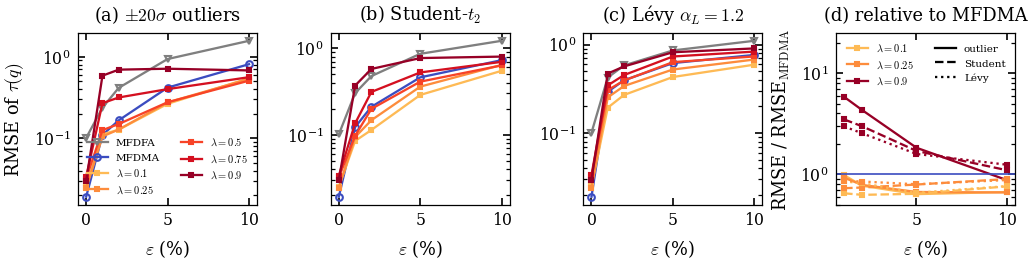

wrote /content/MFQDMA/figures_out/Fig05_contamination.pdf
Fig. 5 (Fig05_contamination) done in 3 s


'Fig05_contamination'

In [14]:
F.make_figure(5)

### Fig. 6. Negative results (α-stable noise, monotone maps)

Negative results. (a) Spurious width of $h(q)$ for independent symmetric $\alpha$-stable noise ($N=2^{15}$, five realizations) versus the stable index. (b) Mean absolute change of $h(q)$ of a log-normal cascade under strictly increasing maps. Bar order in each group: MFDFA, MFDMA, and MFQDMA with $\lambda=0.1$, $0.25$, $0.5$, $0.75$, $0.9$.

*Source:* Reads `advantage_all.json` in `results/`.

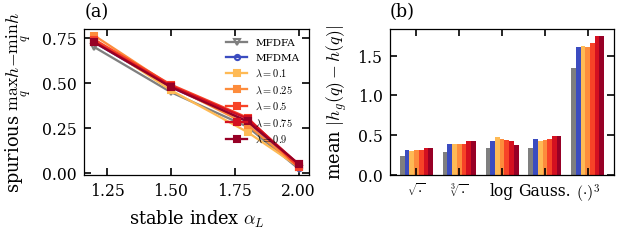

wrote /content/MFQDMA/figures_out/Fig06_negative_results.pdf
Fig. 6 (Fig06_negative_results) done in 1 s


'Fig06_negative_results'

In [15]:
F.make_figure(6)

### Fig. 7. 2D four-multiplier cascade

2D four-multiplier cascade, set A, $512\times512$. (a) Measure normalized by its mean (logarithmic color scale). (b) $F_q(n)$ of backward 2D-MFQDMA ($\lambda=0.25$), shifted vertically. (c) $\Delta\tau(q)$ for backward 2D-MFDMA and 2D-MFQDMA. (d) $f(\alpha)$ versus theory. For this realization $\mathrm{RMSE}_\tau=0.087$ (MFDMA), $0.099$ ($\lambda=0.25$), and $0.084$ ($\lambda=0.5$).

*Source:* Computed directly ($512\times512$ quantile trend, about 2 min).

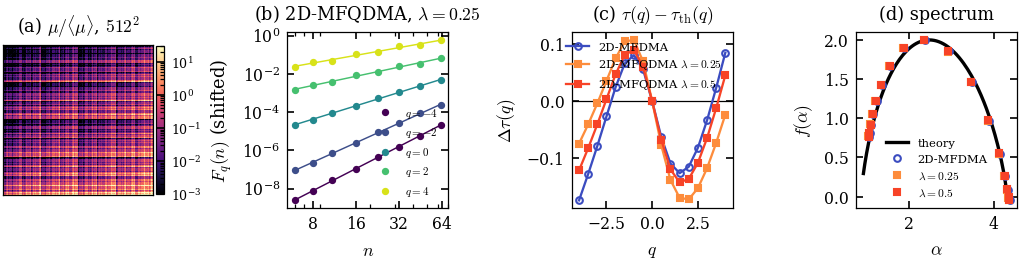

wrote /content/MFQDMA/figures_out/Fig07_cascade2d.pdf
Fig. 7 (Fig07_cascade2d) done in 86 s


'Fig07_cascade2d'

In [16]:
F.make_figure(7)

### Fig. 8. 2D: window position and contamination

(a) $\mathrm{RMSE}_\tau$ of $256^2$ cascades (mean over sets A--C) for all combinations of trend functional and window position. (b), (c) $\mathrm{RMSE}_\tau$ of the set-A cascade ($256^2$) when a fraction $\varepsilon$ of pixels is replaced by $\pm20\sigma$ outliers or Student-$t_2$ values (mean of two replicates).

*Source:* Reads `analysis_2d_all.json` in `results/`.

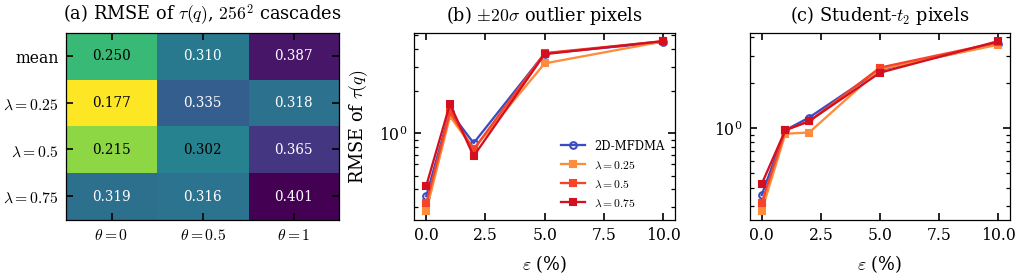

wrote /content/MFQDMA/figures_out/Fig08_2d_theta_contamination.pdf
Fig. 8 (Fig08_2d_theta_contamination) done in 2 s


'Fig08_2d_theta_contamination'

In [17]:
F.make_figure(8)

### Fig. 9. Fractional Brownian surfaces

Fractional Brownian surfaces ($256^2$). (a) $h(2)$ versus $H$ from the raw surface $X$ (dashed) and from its mixed increments $\Delta_1\Delta_2X$ (solid, mean $\pm$ s.d.); the black line is $h=H$. (b) $h(q)$ of the increments for $H=0.3$ (solid) and $H=0.7$ (dashed); horizontal lines mark $H$. (c) $F_q(n)$ of 2D-MFQDMA ($\lambda=0.25$) on the increments of a surface with $H=0.5$.

*Source:* Reads `analysis_2d_all.json`, `paper_2d_mono.json` in `results/`.

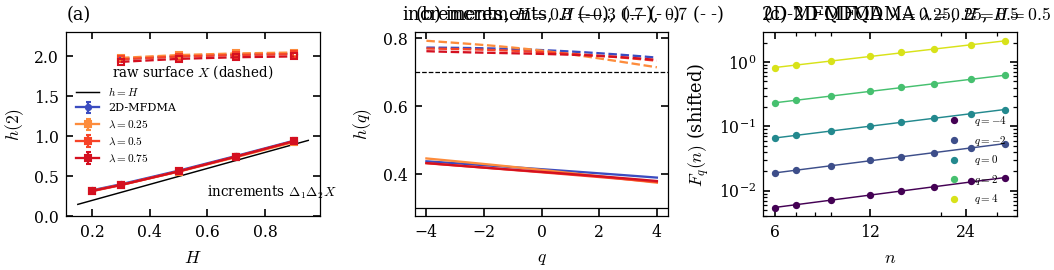

wrote /content/MFQDMA/figures_out/Fig09_2d_monofractal.pdf
Fig. 9 (Fig09_2d_monofractal) done in 3 s


'Fig09_2d_monofractal'

In [18]:
F.make_figure(9)

### Fig. 10. Daily returns: fluctuation functions and spectra

Daily returns. (a) Log returns of the S&P 500, 1950--2015. (b) $F_q(n)$ of backward MFQDMA ($\lambda=0.25$), shifted vertically. (c) $h(q)$ of the S&P 500 for MFDFA, MFDMA, and MFQDMA ($\lambda=0.1$, $0.25$, $0.5$); the dotted line marks $h=1/2$. (d) $f(\alpha)$ of the S&P 500, the SSE Composite, and Bitcoin for MFDMA and MFQDMA ($\lambda=0.25$).

*Source:* Reads the S&P 500 series from qrmdata (cloned into `data/` on first use) and `results/finance.json`.

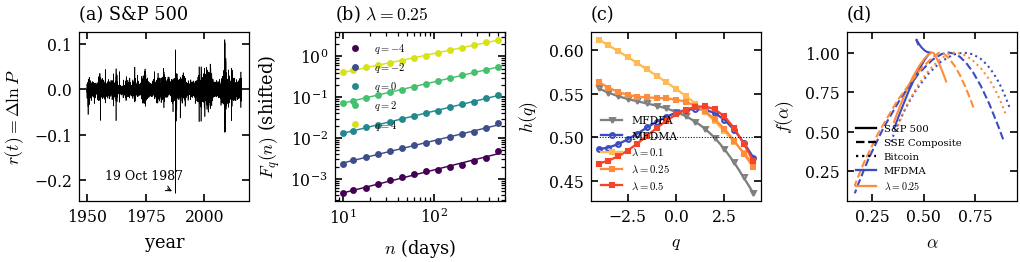

wrote /content/MFQDMA/figures_out/Fig10_finance_spectra.pdf
Fig. 10 (Fig10_finance_spectra) done in 3 s


'Fig10_finance_spectra'

In [19]:
F.make_figure(10)

### Fig. 11. Eighteen assets

Eighteen assets. (a) Spectral width $\Delta\alpha$ of daily returns for MFDFA, MFDMA, and MFQDMA at five quantile levels. (b) Percentage of $\Delta\alpha$ retained by shuffled (open down-triangles) and phase-randomized (filled up-triangles) surrogates, mean of five each; colors as in (a).

*Source:* Reads `finance.json` in `results/`.

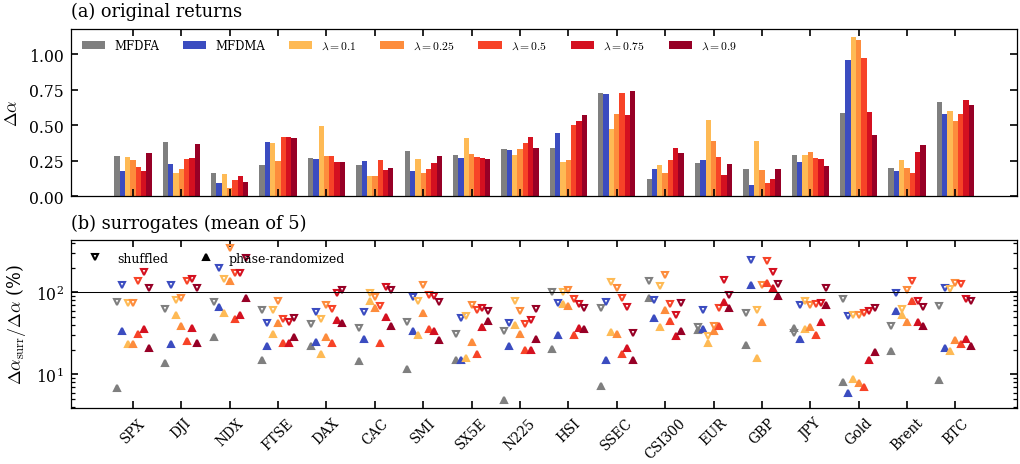

wrote /content/MFQDMA/figures_out/Fig11_finance_markets.pdf
Fig. 11 (Fig11_finance_markets) done in 2 s


'Fig11_finance_markets'

In [20]:
F.make_figure(11)

### Fig. 12. Sensitivity to extremes and data errors

Sensitivity of $h(q)$ of daily returns (median $D_h$ over 18 assets). (a) Removal of the $k$ largest absolute returns. (b) Isolated bad ticks at a fraction $\varepsilon$ of days. (c) Erroneous returns (price level shifts) at a fraction $\varepsilon$ of days. (d) Microstructure noise of relative amplitude $\eta$ on every log price. Colors and markers as in panel (a).

*Source:* Reads `finance.json` in `results/`.

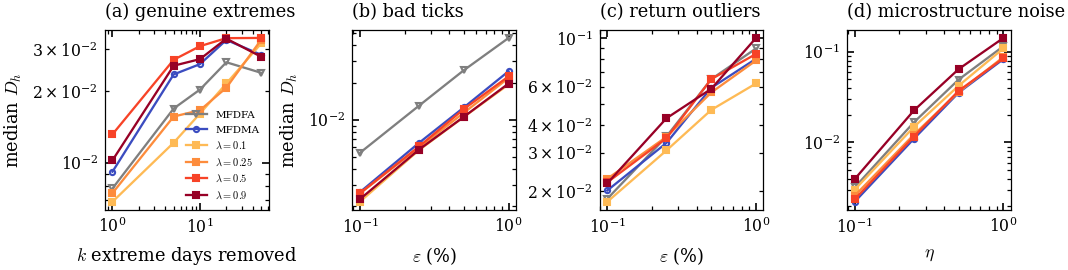

wrote /content/MFQDMA/figures_out/Fig12_finance_robustness.pdf
Fig. 12 (Fig12_finance_robustness) done in 3 s


'Fig12_finance_robustness'

In [21]:
F.make_figure(12)

### Fig. 13. DJIA stocks and rolling windows

(a), (b) Distribution of $D_h$ over 29 DJIA stocks (2000--2015) for 0.5% bad ticks and for microstructure noise with $\eta=0.5$; boxes show quartiles, whiskers the 5%--95% range; labels give the method or $\lambda$. (c) Change of $\Delta\alpha$ caused by 0.5% bad ticks in rolling ten-year windows of the S&P 500 (step: half a year).

*Source:* Reads `results/finance.json` and the S&P 500 series from qrmdata.

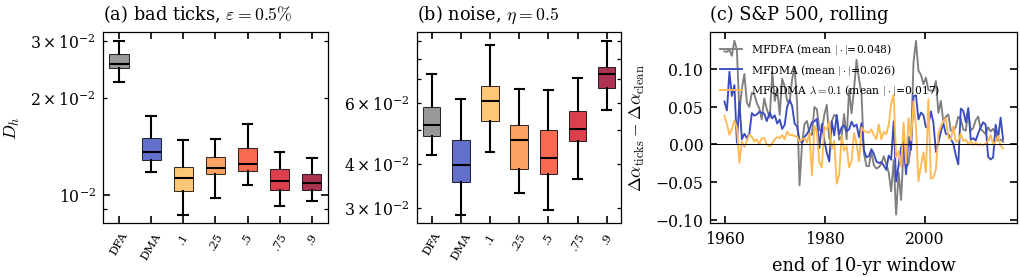

wrote /content/MFQDMA/figures_out/Fig13_finance_stocks_rolling.pdf
Fig. 13 (Fig13_finance_stocks_rolling) done in 2 s


'Fig13_finance_stocks_rolling'

In [22]:
F.make_figure(13)

### Fig. 14. Bonn EEG: surrogates

Bonn EEG, 20 segments per set. (a) Mean spectral width $\Delta\alpha$ of the originals. (b) Fraction of $\Delta\alpha$ retained by shuffled (open down-triangles) and phase-randomized (filled up-triangles) surrogates. (c) Mean fit quality $R^2$. Colors as in (a).

*Source:* Reads `results/real_eeg.json`.

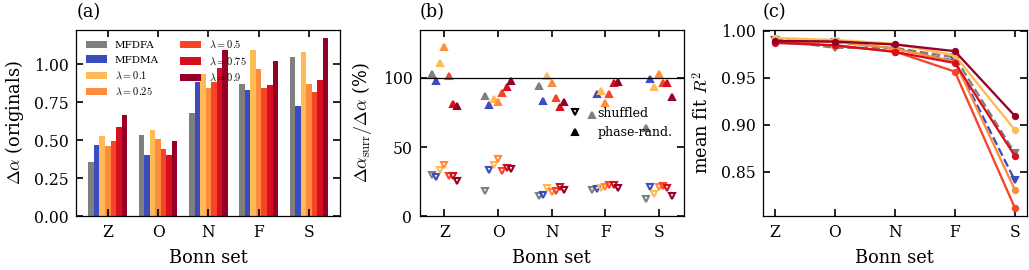

wrote /content/MFQDMA/figures_out/Fig14_eeg_surrogates.pdf
Fig. 14 (Fig14_eeg_surrogates) done in 2 s


'Fig14_eeg_surrogates'

In [23]:
F.make_figure(14)

### Fig. 15. Bonn EEG: λ-resolved exponents

Median $\lambda$-resolved generalized Hurst exponents $h(q,\lambda)$ of the Bonn EEG sets (100 segments each, $\theta=0$, $12\le n\le128$). (a) Z, healthy, eyes open; (b) O, healthy, eyes closed; (c) N, interictal, contralateral; (d) F, interictal, epileptogenic zone; (e) S, ictal.

*Source:* Reads `results/eeg_main.npz`.

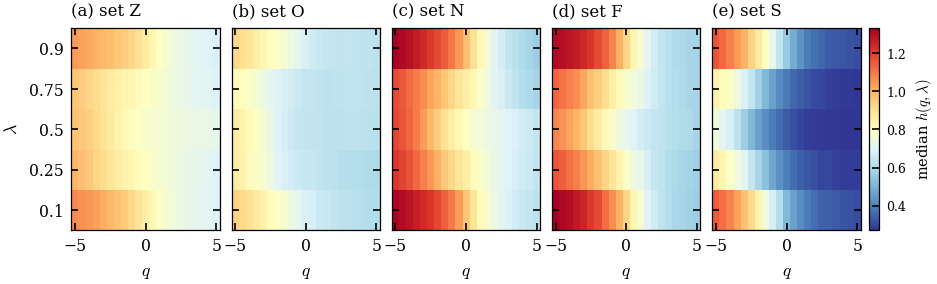

wrote /content/MFQDMA/figures_out/Fig15_eeg_lambda_surfaces.pdf
Fig. 15 (Fig15_eeg_lambda_surfaces) done in 2 s


'Fig15_eeg_lambda_surfaces'

In [24]:
F.make_figure(15)

### Fig. 16. Bonn EEG: information in λ

Information carried by the quantile level (500 EEG segments). (a) $\lambda$-spread $W(q=-5)$ per set. (b) Median $W(q)$ versus $q$. (c) Effect size $|\delta|$ (Cliff) of the F-versus-N contrast for each $(q,\lambda)$. (d) Cross-validated AUC of logistic classifiers using the 21 exponents $h(q)$ of MFDMA or the 21 exponents $h(q,\lambda^*)$ of MFQDMA at the best single $\lambda^*$ (equal feature dimension).

*Source:* Reads `results/eeg_main.npz` and `results/eeg_auc.json`.

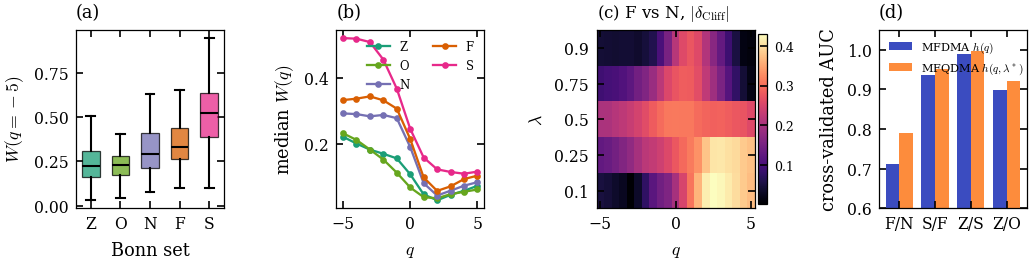

wrote /content/MFQDMA/figures_out/Fig16_eeg_lambda_resolved.pdf
medians W [0.2215, 0.2322, 0.2929, 0.3338, 0.5237] spearman SignificanceResult(statistic=np.float64(0.6021757403942235), pvalue=np.float64(1.169022174824948e-50))
Fig. 16 (Fig16_eeg_lambda_resolved) done in 2 s


'Fig16_eeg_lambda_resolved'

In [25]:
F.make_figure(16)

### Fig. 17. Terrain elevation model

Terrain elevation model. (a) Elevation $X$. (b) Mixed increments $\Delta_1\Delta_2X$. (c) $F_q(n)$ of 2D-MFQDMA ($\lambda=0.25$) on the increments, shifted vertically. (d) $f(\alpha)$ of the increments (solid), of shuffled increments (dotted, clustered near $\alpha\approx1$), and of a 2D phase-randomized surrogate (dashed), for 2D-MFDMA and 2D-MFQDMA.

*Source:* Computed directly (about 2 min). The elevation model ships with Matplotlib.

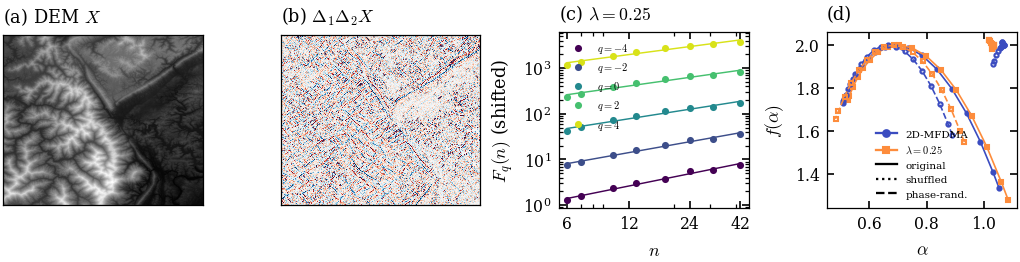

wrote /content/MFQDMA/figures_out/Fig17_terrain_dem.pdf
DEM orig MFDMA h2=0.622 dalpha=0.545 R2=0.9703
DEM orig 0.25 h2=0.634 dalpha=0.559 R2=0.9733
DEM orig 0.5 h2=0.589 dalpha=0.588 R2=0.9648
DEM orig 0.75 h2=0.631 dalpha=0.696 R2=0.9719
DEM shuf MFDMA h2=1.064 dalpha=0.037 R2=0.9997
DEM shuf 0.25 h2=1.035 dalpha=0.017 R2=0.9994
DEM shuf 0.5 h2=1.060 dalpha=0.045 R2=0.9996
DEM shuf 0.75 h2=1.066 dalpha=0.135 R2=0.9993
DEM phase MFDMA h2=0.617 dalpha=0.379 R2=0.9688
DEM phase 0.25 h2=0.623 dalpha=0.449 R2=0.9698
DEM phase 0.5 h2=0.589 dalpha=0.403 R2=0.9650
DEM phase 0.75 h2=0.630 dalpha=0.398 R2=0.9718
Fig. 17 (Fig17_terrain_dem) done in 124 s


'Fig17_terrain_dem'

In [26]:
F.make_figure(17)

## 3. Tables

Every data table of the paper is generated from `results/` by `mfqdma/tables_paperI.py`; the LaTeX body rows are written to `tables_out/`. Table I (the benchmark corpus) and Table XIII (guidelines) contain no computed numbers.

In [27]:
from mfqdma import tables_paperI as T

### Table II

RMSE of $\tau(q)$ (mean ± s.d.) over the eight binomial measures.

In [28]:
display(T.table2_binomial())

,θ,RMSE_τ
Method,,
MFDFA,---,0.155 ± 0.054
MFDMA,0,0.025 ± 0.016
MFDMA,1/2,0.142 ± 0.034
MFDMA,1,0.041 ± 0.026
"MFQDMA, λ=0.10",0,0.029 ± 0.020
"MFQDMA, λ=0.25",0,0.029 ± 0.018
"MFQDMA, λ=0.50",0,0.032 ± 0.015
"MFQDMA, λ=0.75",0,0.031 ± 0.012
"MFQDMA, λ=0.90",0,0.029 ± 0.009


### Table III

RMSE of $h(q)$ versus $H$ (mean ± s.d.) over 18 fGn series ($N=2^{16}$).

In [29]:
display(T.table3_fgn())

,θ,RMSE_h
Method,,
MFDFA,---,0.023 ± 0.022
MFDMA,0,0.028 ± 0.020
MFDMA,1/2,0.006 ± 0.003
MFDMA,1,0.028 ± 0.021
"MFQDMA, λ=0.10",0,0.028 ± 0.017
"MFQDMA, λ=0.25",0,0.034 ± 0.021
"MFQDMA, λ=0.50",0,0.031 ± 0.021
"MFQDMA, λ=0.75",0,0.025 ± 0.022
"MFQDMA, λ=0.90",0,0.021 ± 0.014


### Table IV

RMSE of $\tau(q)$ of the contaminated binomial measure ($p=0.3$, $N=2^{16}$, mean of five replicates).

In [30]:
display(T.table4_contamination())

clean values (ε=0): MFDFA 0.101, MFDMA (θ=0) 0.019, MFQDMA λ=0.10 0.025, MFQDMA λ=0.25 0.024, MFQDMA λ=0.50 0.032, MFQDMA λ=0.75 0.034, MFQDMA λ=0.90 0.030


,outlier 1%,outlier 2%,outlier 5%,outlier 10%,student_t 1%,student_t 2%,student_t 5%,student_t 10%,levy 1%,levy 2%,levy 5%,levy 10%
MFDFA,0.237,0.415,0.938,1.570,0.302,0.476,0.862,1.219,0.424,0.581,0.858,1.102
MFDMA (θ=0),0.110,0.166,0.418,0.810,0.122,0.210,0.460,0.728,0.293,0.395,0.618,0.764
MFQDMA λ=0.10,0.111,0.127,0.264,0.545,0.085,0.113,0.288,0.548,0.194,0.270,0.430,0.593
MFQDMA λ=0.25,0.105,0.128,0.275,0.534,0.094,0.147,0.359,0.641,0.253,0.340,0.522,0.677
MFQDMA λ=0.50,0.126,0.149,0.276,0.509,0.097,0.199,0.410,0.633,0.306,0.392,0.633,0.734
MFQDMA λ=0.75,0.269,0.316,0.400,0.561,0.135,0.312,0.525,0.696,0.346,0.453,0.733,0.833
MFQDMA λ=0.90,0.586,0.694,0.713,0.679,0.369,0.576,0.769,0.800,0.470,0.566,0.818,0.905


### Table V

RMSE of $\tau(q)$ of 2D cascades, backward windows.

In [31]:
display(T.table5_cascade2d())

,256² A,256² B,256² C,512² A,512² B,512² C
Moving mean,0.356,0.196,0.197,0.087,0.050,0.115
λ=0.25,0.279,0.128,0.125,0.099,0.040,0.137
λ=0.50,0.316,0.173,0.157,0.084,0.039,0.115
λ=0.75,0.422,0.282,0.252,0.109,0.103,0.112


### Table VI

$h(2)$ of the mixed increments of fractional Brownian surfaces: mean of three realizations, standard deviation in units of the last digit.

In [32]:
display(T.table6_mono2d())

,2D-MFDMA,λ=0.25,λ=0.5,λ=0.75
H,,,,
0.2,0.327(13),0.321(17),0.315(13),0.320(7)
0.3,0.402(16),0.394(21),0.391(17),0.394(10)
0.5,0.572(22),0.559(28),0.563(24),0.562(16)
0.7,0.756(29),0.741(35),0.749(31),0.748(23)
0.9,0.946(35),0.929(41),0.940(37),0.940(29)


### Table VII

Daily log returns of 18 assets: period, length, excess kurtosis, spectral widths, and the percentage of $\Delta\alpha$ retained by shuffled and phase-randomized surrogates.

In [33]:
display(T.table7_markets())

,Period,N,κ,Δα MFDFA,Δα MFDMA,Δα λ=0.1,Δα λ=0.25,Δα λ=0.5,shuf% MFDMA,shuf% λ=0.1,phase% MFDMA,phase% λ=0.1
Asset,,,,,,,,,,,,
S&P 500,1950--15,16606,27.3,0.28,0.18,0.27,0.25,0.21,123,73,34,24
DJIA,1985--15,7796,41.9,0.38,0.23,0.17,0.19,0.26,124,80,24,52
NASDAQ-100,1985--15,7627,7.5,0.16,0.09,0.16,0.06,0.12,201,146,66,56
FTSE 100,1984--15,8332,9.7,0.22,0.38,0.38,0.25,0.42,43,61,22,31
DAX,1990--15,6354,4.6,0.27,0.26,0.49,0.29,0.29,57,47,25,18
CAC 40,1990--15,6548,4.4,0.22,0.25,0.14,0.15,0.26,57,97,27,80
SMI,1990--15,6349,6.4,0.32,0.18,0.26,0.17,0.19,88,79,34,31
Euro Stoxx 50,1987--15,7444,5.7,0.29,0.27,0.41,0.30,0.28,49,51,15,16
Nikkei 225,1984--15,7879,8.0,0.33,0.32,0.29,0.33,0.37,43,78,22,40


### Table VIII

Sensitivity $D_h$ ($\times10^3$) of $h(q)$ of daily returns to genuine extremes and injected data errors (median over 18 assets or 29 DJIA stocks).

In [34]:
display(T.table8_finrobust())

,Top5 D_h,Top5 |δΔα|,Bad ticks Mkts,Bad ticks Stocks,Outliers Mkts,Outliers Stocks,Noise Mkts,Noise Stocks,Rolling |δΔα|
Method,,,,,,,,,
MFDFA,16.9,0.067,25.1,25.6,65.1,71.8,49.4,51.9,0.048
MFDMA (θ=0),23.5,0.058,12.6,13.5,59.4,65.8,35.4,39.7,0.026
MFQDMA λ=0.1,12.2,0.024,10.5,11.3,47.1,59.4,42.2,60.8,0.017
MFQDMA λ=0.25,15.7,0.037,11.4,12.1,56.6,60.1,36.0,46.9,0.020
MFQDMA λ=0.5,27.1,0.071,12.2,12.5,65.1,68.9,37.1,41.8,0.025
MFQDMA λ=0.75,27.3,0.057,10.6,11.0,66.1,79.7,43.1,50.5,---
MFQDMA λ=0.9,25.6,0.039,10.6,10.8,58.8,86.5,64.4,72.6,---


### Table IX

Sensitivity of the EEG exponents to preprocessing: mean $|\Delta h(q,1/2)|$ relative to the unprocessed data.

In [35]:
display(T.table9_preprocessing())

,"mean |Δh(q,1/2)|"
Operation,
$z$ scoring,0.0000
50 Hz notch,0.0004
Linear detrending,0.0062
Downsampling by 2,0.0331
"FIR high-pass, 0.5 Hz",0.1126
"FIR band-pass, 1-40 Hz",0.2988


### Table X

Bonn EEG, 20 segments per set: $\Delta\alpha$ of the originals and percentage retained by surrogates.

In [36]:
display(T.table10_eeg())

,Δα Z,Δα O,Δα N,Δα F,Δα S,shuf% Z,shuf% O,shuf% N,shuf% F,shuf% S,phase% Z,phase% O,phase% N,phase% F,phase% S
Method,,,,,,,,,,,,,,,
MFDFA,0.360,0.535,0.681,0.870,1.050,30,18,15,19,12,103,87,94,74,64
MFDMA,0.471,0.401,0.882,0.830,0.724,29,33,16,20,21,97,80,83,88,99
MFQDMA λ=0.10,0.526,0.568,0.934,1.095,1.080,33,37,21,20,16,111,85,101,91,94
MFQDMA λ=0.25,0.461,0.510,0.847,0.968,0.871,37,42,17,21,21,122,83,96,82,103
MFQDMA λ=0.50,0.496,0.444,0.886,0.847,0.817,29,33,19,22,22,101,89,85,89,96
MFQDMA λ=0.75,0.586,0.406,0.978,0.863,0.895,29,35,21,22,20,81,93,79,96,96
MFQDMA λ=0.90,0.664,0.497,1.097,1.022,1.170,25,34,19,20,15,79,98,83,97,86


### Table XI

Cross-validated AUC ($10\times10$ folds) of classifiers based on 21 exponents.

In [37]:
display(T.table11_auc())

,MFDMA h(q),"MFQDMA h(q,λ*)",λ*
Contrast,,,
F vs N,0.711,0.791,0.75
S vs F,0.938,0.951,0.90
Z vs S,0.991,0.998,0.10/0.90
Z vs O,0.898,0.922,0.10/0.90


### Table XII

Terrain elevation model: raw surface, mixed increments and surrogates.

In [38]:
display(T.table12_dem())

,h(2) raw,h(2) incr.,Δα orig.,Δα shuf.,Δα phase,R²
Trend,,,,,,
MFDMA,1.963,0.622,0.545,0.037,0.379,0.970
MFDMA θ=1/2,1.923,0.661,0.524,---,---,0.963
λ=0.25,1.954,0.634,0.559,0.017,0.449,0.973
λ=0.50,1.959,0.589,0.588,0.045,0.403,0.965
λ=0.75,1.960,0.631,0.696,0.135,0.398,0.972


## 4. Check against the manuscript

Compares each regenerated figure (`figures_out/`) with the figure in the submitted manuscript (`figures/`). "identical" means pixel-identical PNG files, "close" that fewer than 1% of the pixels differ noticeably. The reference figures were drawn with Matplotlib 3.11 and its bundled DejaVu/Computer Modern fonts; with another Matplotlib version, small rendering differences (anti-aliasing, glyph placement) can make figures with identical data show up as "DIFFERS". The numbers themselves are checked by the tables in Part 3, which can be compared with the paper directly.

In [ ]:
from mfqdma.verify import compare_figures
display(compare_figures())

## 5. Download the outputs

In [ ]:
#@title Collect all regenerated figures, tables and results in one zip file
import shutil
from mfqdma import paths
stage = paths.REPO / '_export'
shutil.rmtree(stage, ignore_errors=True)
for d in ('figures_out', 'tables_out', 'results'):
    if (paths.REPO / d).is_dir():
        shutil.copytree(paths.REPO / d, stage / d)
archive = shutil.make_archive(str(paths.REPO / 'MFQDMA_PaperI_outputs'), 'zip', stage)
shutil.rmtree(stage)
print('wrote', archive)
if IN_COLAB:
    from google.colab import files
    files.download(archive)